In [1]:
import os
os.environ["WANDB_MODE"] = "disabled"  # OKB calls wandb.log/define_metric internally; no-ops these

import sys
OKB_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "RM", "sf-fsa-vi"))
for root in (OKB_ROOT, SF_FSA_VI_ROOT):
    if root not in sys.path:
        sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import wandb
wandb.init(mode="disabled")

# `Office-v0` is registered under old `gym` (RM/sf-fsa-vi/envs/__init__.py), while OKB is
# built on `gymnasium` -- both packages are installed side by side in the `okb` env
# specifically so this notebook can bridge them (see Section 1 below).
import gym as old_gym
import gymnasium as gym
from gymnasium import spaces
import envs  # noqa: F401 -- registers Office-v0 (and Delivery-v0, DoubleSlit-v0, ...) in old gym

from rl.successor_features.okb import OKB
from rl.successor_features.ols import OLS
from rl.utils.utils import seed_everything
from rl.utils.eval import policy_evaluation_mo

%matplotlib inline

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/flax/configurations.py:42: DeprecationWarning: jax.config.define_bool_state is deprecated. Please use other libraries for configuration instead.
  return jax_config.define_bool_state('flax_' + name, default, help)


In [2]:
SEED = 0
GAMMA = 0.99
ADD_OBJ_TO_START = True   # mirrors office_ccs_results.ipynb: register every object cell as a valid start state too
PHI_OBJ_TYPES = ["C1", "C2", "O1", "O2", "M1", "M2"]

seed_everything(SEED)

In [3]:
class OfficeGymnasiumEnv(gym.Env):
    """Wraps sf-fsa-vi's old-gym `Office-v0` so it satisfies OKB's gymnasium contract:
    5-tuple step/reset, gymnasium space classes, `reward_dim`/`reward_space`, and the
    per-feature vector `info['phi']` returned as the actual reward.
    """

    def __init__(self, add_obj_to_start=True, random_act_prob=0.0):
        self._env = old_gym.make("Office-v0", add_obj_to_start=add_obj_to_start, random_act_prob=random_act_prob)
        self.core = self._env.unwrapped  # the raw Office instance -- MAP, initial states, feat_dim, ...
        self.height, self.width = self.core.height, self.core.width

        self.action_space = spaces.Discrete(self.core.action_space.n)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32)

        self.reward_dim = self.core.feat_dim
        self.reward_space = spaces.Box(low=0.0, high=1.0, shape=(self.reward_dim,), dtype=np.float32)

    def _normalize(self, obs):
        # raw obs is (row, col) as integers; Box declares [0, 1], so normalize to match
        return np.array([obs[0] / (self.height - 1), obs[1] / (self.width - 1)], dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self._env.seed(seed)
        state = None if options is None else options.get("state")
        obs = self._env.reset(state=state)
        return self._normalize(obs), {}

    def step(self, action):
        obs, _scalar_reward, done, info = self._env.step(int(action))
        # old gym's TimeLimit wrapper (applied via gym.envs.register(max_episode_steps=200))
        # flags truncation this way instead of a separate return value
        truncated = info.pop("TimeLimit.truncated", False)
        terminated = bool(done) and not truncated
        reward = info["phi"].astype(np.float32)
        # `rl.utils.eval.eval_mo`/`policy_evaluation_mo` (used by SFOLS's GPI-based next_w,
        # Section 5 below) read the vector reward from `info["vector_reward"]`, not from the
        # return value -- populate it here too so those functions work directly with this env.
        info["vector_reward"] = reward
        return self._normalize(obs), reward, terminated, truncated, info


office_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
office_eval_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
print(f"action_space: {office_env.action_space}   observation_space: {office_env.observation_space}")
print(f"reward_dim: {office_env.reward_dim}   reward_space: {office_env.reward_space}")

action_space: Discrete(4)   observation_space: Box(0.0, 1.0, (2,), float32)
reward_dim: 6   reward_space: Box(0.0, 1.0, (6,), float32)


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment Office-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `Office-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [4]:
print("isinstance(action_space, gymnasium Discrete):", isinstance(office_env.action_space, spaces.Discrete))
print("unwrapped is self:", office_env.unwrapped is office_env)

obs, info = office_env.reset()
print(f"\nreset()  -> obs={obs} (dtype={obs.dtype}), info={info}")

obs, reward, terminated, truncated, info = office_env.step(office_env.action_space.sample())
print(f"step()   -> obs={obs}, reward={reward} (shape={reward.shape}), "
      f"terminated={terminated}, truncated={truncated}, info={info}")

# a throwaway OKB agent, built (not trained) purely to confirm __init__ wires up cleanly
_probe_agent = OKB(
    office_env, phi_dim=office_env.reward_dim, num_nets=2, net_arch=[32, 32], ok_net_arch=[32, 32],
    buffer_size=1000, batch_size=8, learning_starts=10, log=False, seed=SEED,
    project_name="office-okb-probe", experiment_name="probe",
)
print(f"\nOKB constructed successfully: phi_dim={_probe_agent.phi_dim}, action_dim={_probe_agent.action_dim}")
del _probe_agent

isinstance(action_space, gymnasium Discrete): True
unwrapped is self: True

reset()  -> obs=[1. 1.] (dtype=float32), info={}
step()   -> obs=[1.  0.9], reward=[0. 0. 0. 0. 0. 0.] (shape=(6,)), terminated=False, truncated=False, info={'phi': array([0., 0., 0., 0., 0., 0.], dtype=float32), 'proposition': ' ', 'vector_reward': array([0., 0., 0., 0., 0., 0.], dtype=float32)}



OKB constructed successfully: phi_dim=6, action_dim=4


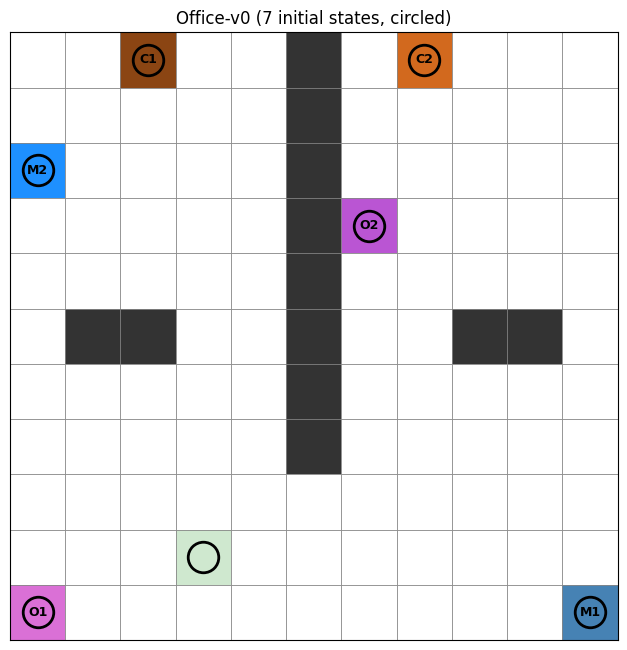

In [5]:
MAP = office_env.core.MAP
height, width = MAP.shape

color_map = {"X": "#333333", "_": "#cfe8cf", " ": "#ffffff"}
object_colors = {
    "C1": "#8B4513", "C2": "#D2691E",
    "M1": "#4682B4", "M2": "#1E90FF",
    "O1": "#DA70D6", "O2": "#BA55D3",
}
color_map.update(object_colors)


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            sym = MAP[r, c]
            color = color_map.get(sym, "#ffffff")
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if sym not in ("X", " ", "_"):
                ax.text(*cell_center(r, c), sym, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
for s in office_env.core.initial:
    x, y = cell_center(*s)
    ax.plot(x, y, marker="o", markersize=22, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=5)
ax.set_title(f"Office-v0 ({len(office_env.core.initial)} initial states, circled)")
plt.tight_layout()
plt.show()

In [6]:
ACTIONS = {
    office_env.core.LEFT: "LEFT",
    office_env.core.UP: "UP",
    office_env.core.RIGHT: "RIGHT",
    office_env.core.DOWN: "DOWN",
}
print("Action space:", ACTIONS)

print("\nInitial-state distribution (uniform over these, one drawn per reset()):")
for s in office_env.core.initial:
    print(f"  {s}  ({MAP[s]!r})")


def demo_step(start_state, action):
    obs, info = office_env.reset(options={"state": start_state})
    obs, reward, terminated, truncated, info = office_env.step(action)
    print(f"\nstart={start_state}  action={ACTIONS[action]}"
          f"\n  -> new state={tuple(office_env.core.state)}  reward(phi)={reward}"
          f"\n  -> terminated={terminated}  proposition={info['proposition']!r}")


# 1. A plain move: nothing special, just S -> S' under P
demo_step(start_state=(9, 3), action=office_env.core.UP)

# 2. A wall bump: (0,4) --RIGHT--> (0,5) is 'X', so P self-loops back to (0,4)
demo_step(start_state=(0, 4), action=office_env.core.RIGHT)

# 3. Landing on an object: (0,1) --RIGHT--> (0,2) is 'C1' -> reward fires, episode ends
demo_step(start_state=(0, 1), action=office_env.core.RIGHT)

Action space: {0: 'LEFT', 1: 'UP', 2: 'RIGHT', 3: 'DOWN'}

Initial-state distribution (uniform over these, one drawn per reset()):
  (2, 0)  ('M2')
  (10, 0)  ('O1')
  (0, 2)  ('C1')
  (9, 3)  ('_')
  (3, 6)  ('O2')
  (0, 7)  ('C2')
  (10, 10)  ('M1')

start=(9, 3)  action=UP
  -> new state=(8, 3)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 4)  action=RIGHT
  -> new state=(0, 4)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 1)  action=RIGHT
  -> new state=(0, 2)  reward(phi)=[1. 0. 0. 0. 0. 0.]
  -> terminated=True  proposition='C1'


In [7]:
import random

class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def gpi_action(rng, state, w, sf_tables):
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)
    action_values = values.max(axis=0)
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


NUM_STEPS_PER_POLICY = 100_000

def solve_task(env, w, num_steps=NUM_STEPS_PER_POLICY, alpha=0.1, gamma=GAMMA,
               eps_start=1.0, eps_end=0.05, seed=0):
    rng = random.Random(seed)
    n_actions = env.action_space.n
    feat_dim = env.reward_dim

    # one-hot on argmax(w): a tight optimistic upper bound since Office's features are
    # mutually exclusive (touching any object ends the episode).
    optimistic_vec = np.zeros(feat_dim, dtype=np.float32)
    optimistic_vec[np.argmax(w)] = 1.0
    default_vec = np.tile(optimistic_vec, (n_actions, 1))
    psi = SFTable(n_actions, feat_dim, default_vec)

    obs, _ = env.reset()
    state = tuple(env.core.state)
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / (0.5 * num_steps))
        if rng.random() < eps:
            action = rng.randrange(n_actions)
        else:
            action = gpi_action(rng, state, w, [psi])

        _, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)

        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(env.core.state)
        else:
            state = next_state
    return psi


def expected_sf(psi_table, w, initial_states):
    vecs = [psi_table[tuple(s0)][np.argmax(psi_table[tuple(s0)] @ w)] for s0 in initial_states]
    return np.mean(vecs, axis=0)


def new_policy(env, w, num_steps=NUM_STEPS_PER_POLICY, seed=0):
    psi_table = solve_task(env, w, num_steps=num_steps, seed=seed)
    psi_w = expected_sf(psi_table, w, env.core.initial)
    return psi_table, psi_w

d = office_env.reward_dim
simplex_corner_weights = [np.eye(d)[i] for i in range(d)]
w_uniform = np.full(d, 1 / d, dtype=np.float32)

Pi_corners, Psi_corners = [], []
for i, w in enumerate(simplex_corner_weights):
    pi_w, psi_w = new_policy(office_env, w, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + i)
    Pi_corners.append(pi_w)
    Psi_corners.append(psi_w)
    print(f"corner {i} ({PHI_OBJ_TYPES[i]})  w={w}  psi={psi_w.round(3)}  value={np.dot(psi_w, w):.3f}")

corner 0 (C1)  w=[1. 0. 0. 0. 0. 0.]  psi=[0.899 0.    0.    0.    0.    0.   ]  value=0.899


corner 1 (C2)  w=[0. 1. 0. 0. 0. 0.]  psi=[0.   0.89 0.   0.   0.   0.  ]  value=0.890


corner 2 (O1)  w=[0. 0. 1. 0. 0. 0.]  psi=[0.    0.    0.921 0.    0.    0.   ]  value=0.921


corner 3 (O2)  w=[0. 0. 0. 1. 0. 0.]  psi=[0.    0.    0.    0.912 0.    0.   ]  value=0.912


corner 4 (M1)  w=[0. 0. 0. 0. 1. 0.]  psi=[0.    0.    0.    0.    0.903 0.   ]  value=0.903


corner 5 (M2)  w=[0. 0. 0. 0. 0. 1.]  psi=[0.    0.    0.    0.    0.    0.904]  value=0.904


psi_uniform=[0.143 0.143 0.281 0.143 0.143 0.143]  value=0.166


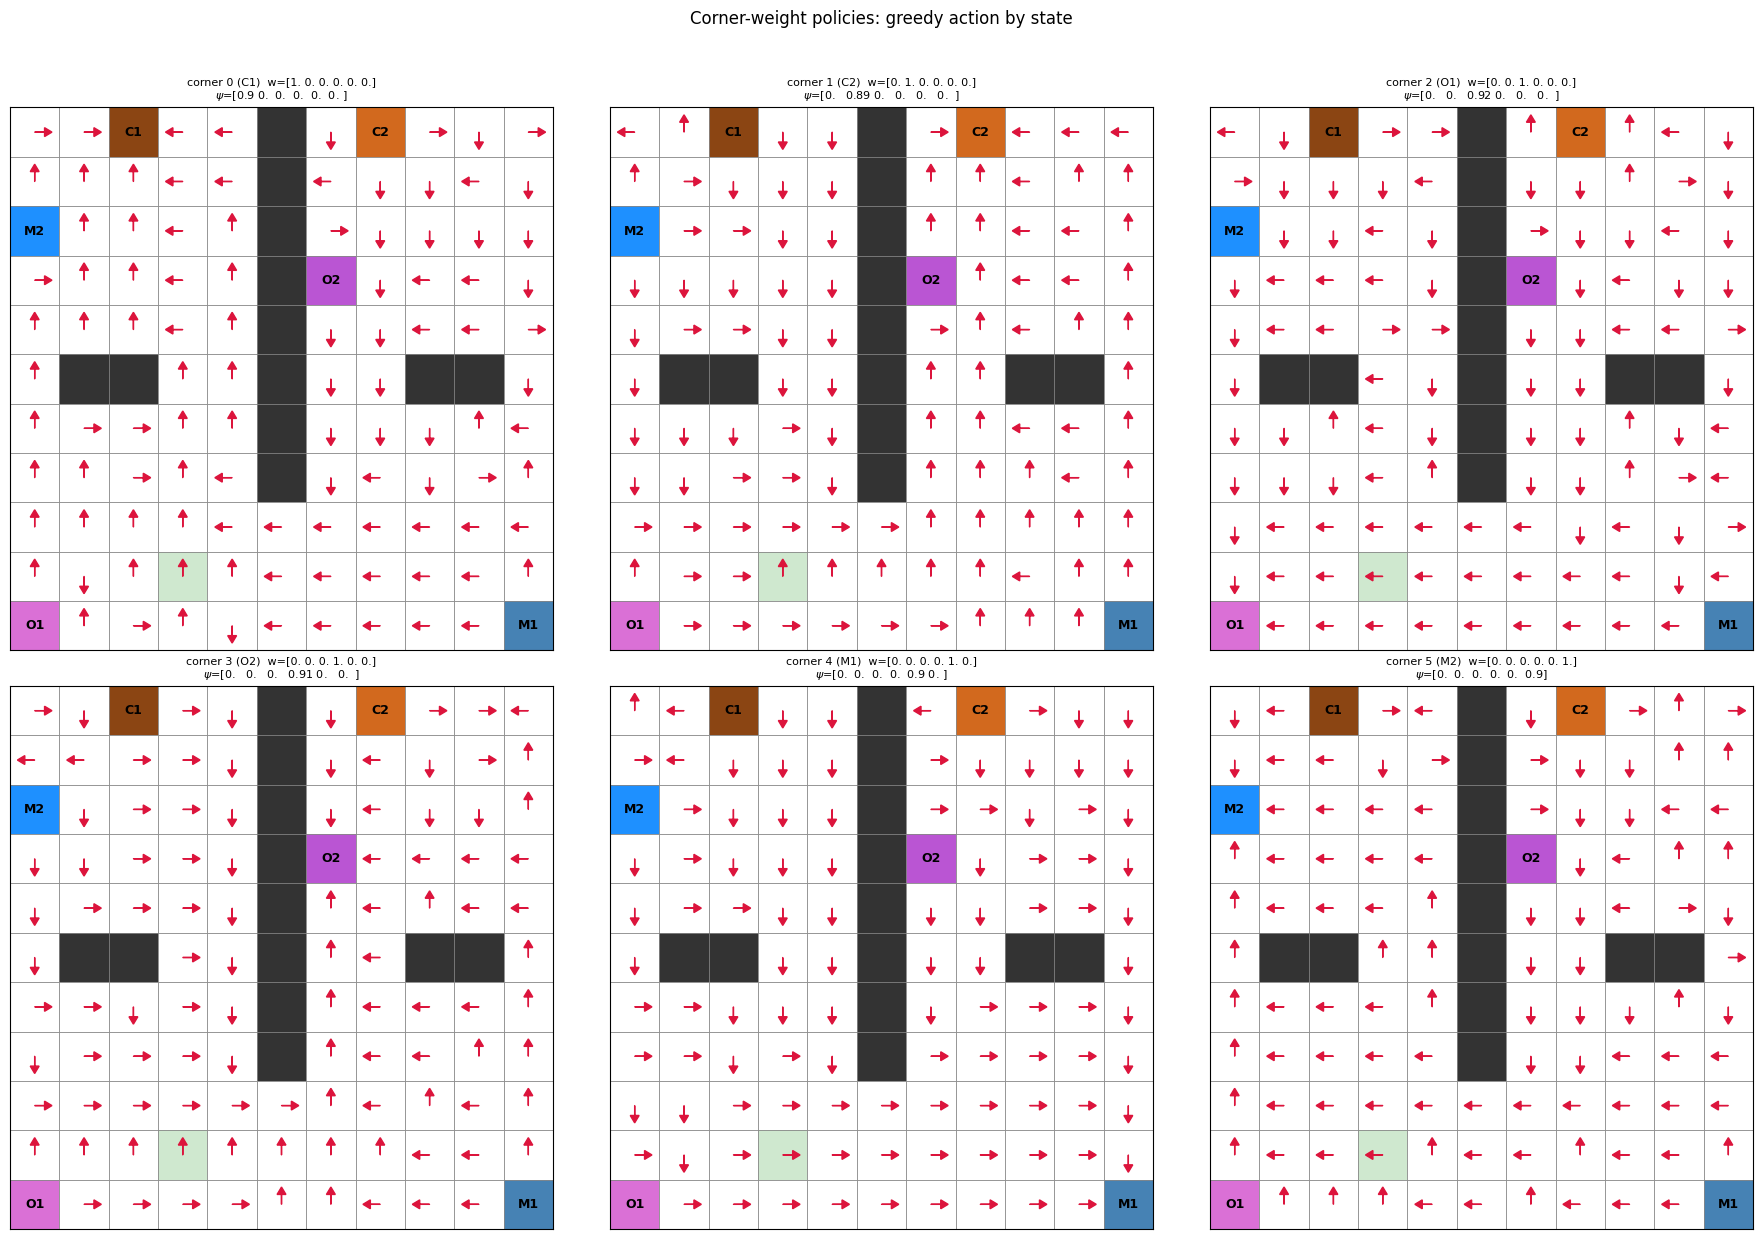

In [8]:
ACTION_DELTAS = {
    office_env.core.LEFT: (-1, 0),
    office_env.core.RIGHT: (1, 0),
    office_env.core.UP: (0, 1),
    office_env.core.DOWN: (0, -1),
}


def plot_policy_arrows(ax, psi_table, w, arrow_len=0.35):
    draw_domain(ax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_"):
                continue
            state = (r, c)
            action = int(np.argmax(psi_table[state] @ w))
            dcol, drow = ACTION_DELTAS[action]
            x, y = cell_center(r, c)
            ax.arrow(x, y, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=6)

pi_uniform, psi_uniform = new_policy(office_env, w_uniform, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + 100)
print(f"psi_uniform={psi_uniform.round(3)}  value={np.dot(psi_uniform, w_uniform):.3f}")

fig, axes = plt.subplots(2, 3, figsize=(width * 0.55 * 3, height * 0.55 * 2))
axes = axes.reshape(-1)

for i, ax in enumerate(axes):
    plot_policy_arrows(ax, Pi_corners[i], simplex_corner_weights[i])
    ax.set_title(f"corner {i} ({PHI_OBJ_TYPES[i]})  w={simplex_corner_weights[i]}\n"
                 + r"$\psi$=" + f"{Psi_corners[i].round(2)}", fontsize=8)

fig.suptitle("Corner-weight policies: greedy action by state", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F


class MetaPolicy(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + task_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def logits(self, s, w):
        return self.net(torch.cat([s, w], dim=-1))
    def forward(self, s, w):
        return F.softmax(self.logits(s, w), dim=-1)

class MetaCritic(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + 2 * task_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def forward(self, s, z, w):
        return self.net(torch.cat([s, z, w], dim=-1))


class ReplayBuffer:
    def __init__(self, capacity, state_dim, task_dim):
        self.s = np.zeros((capacity, state_dim), dtype=np.float32)
        self.z = np.zeros((capacity, task_dim), dtype=np.float32)
        self.phi = np.zeros((capacity, task_dim), dtype=np.float32)
        self.s_next = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros((capacity,), dtype=np.float32)
        self.capacity, self.ptr, self.size = capacity, 0, 0

    def add(self, s, z, phi, s_next, done):
        i = self.ptr
        self.s[i], self.z[i], self.phi[i] = s, z, phi
        self.s_next[i], self.done[i] = s_next, float(done)
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.size, size=batch_size)
        return self.s[idx], self.z[idx], self.phi[idx], self.s_next[idx], self.done[idx]

In [10]:
def train_ok(env, omega, psi_omega, W_sup, Pi_base, eval_env=None, num_steps=200_000, batch_size=256,
             gamma=GAMMA, actor_lr=3e-4, critic_lr=1e-3, buffer_capacity=10_000,
             noise_std_start=2.0, noise_std_end=0.1, noise_decay_frac=1.0,
             tau=0.005, policy_delay=2, target_noise_std=0.5, seed=0,
             min_iter=30_000, critic_warmup_steps=20_000, eval_interval=1000):
    rng = np.random.default_rng(seed)
    py_rng = random.Random(seed)
    eval_env = env if eval_env is None else eval_env
    task_dim = env.reward_dim
    state_dim = 2
    buffer = ReplayBuffer(buffer_capacity, state_dim, task_dim)
    W_sup_arr = np.stack(W_sup).astype(np.float32)

    core_map = env.core.MAP
    all_states = [(r, c) for r in range(core_map.shape[0]) for c in range(core_map.shape[1]) if core_map[r, c] != "X"]

    def random_reset():
        obs, _ = env.reset(options={"state": all_states[py_rng.randrange(len(all_states))]})
        return obs

    def eval_omega(omega_net, w_eval, max_steps=200):
        # runs on a *separate* env instance -- the training loop below tracks its own
        # obs/state across iterations rather than re-querying env each step, so reusing
        # `env` here would silently desync it mid-episode.
        w_t_eval = torch.as_tensor(w_eval, dtype=torch.float32).unsqueeze(0)
        total = 0.0
        for s0 in eval_env.core.initial:
            o, _ = eval_env.reset(options={"state": s0})
            s = tuple(eval_env.core.state)
            disc, ret = 1.0, 0.0
            for _ in range(max_steps):
                with torch.no_grad():
                    z = omega_net(torch.as_tensor(o).unsqueeze(0), w_t_eval).squeeze(0).numpy()
                a = gpi_action(py_rng, s, z, Pi_base)
                o, phi, term, trunc, _ = eval_env.step(a)
                s = tuple(eval_env.core.state)
                ret += disc * float(np.dot(phi, w_eval))
                disc *= gamma
                if term or trunc:
                    break
            total += ret
        return total / len(eval_env.core.initial)

    omega_t, psi_t = copy.deepcopy(omega), copy.deepcopy(psi_omega)
    for p in omega_t.parameters(): p.requires_grad_(False)
    for p in psi_t.parameters(): p.requires_grad_(False)

    actor_opt = torch.optim.Adam(omega.parameters(), lr=actor_lr)
    critic_opt = torch.optim.Adam(psi_omega.parameters(), lr=critic_lr)

    def sample_w(n):
        return W_sup_arr[rng.integers(len(W_sup_arr), size=n)]

    actor_steps = num_steps - critic_warmup_steps

    w_t = sample_w(1)[0]
    obs = random_reset()
    state = tuple(env.core.state)
    losses, value_snapshots, eval_snapshots = [], [], []
    track_states = [torch.as_tensor(env._normalize(s0)).unsqueeze(0) for s0 in env.core.initial]
    track_w = torch.as_tensor(W_sup_arr[0]).unsqueeze(0)
    best_val, best_state = -np.inf, None

    for t in range(num_steps):
        if t > 0 and (terminated or truncated):
            w_t = sample_w(1)[0]
            obs = random_reset()
            state = tuple(env.core.state)

        if t < critic_warmup_steps:
            noise_std = noise_std_start
        else:
            t_since_warmup = t - critic_warmup_steps
            noise_std = max(noise_std_end, noise_std_start - (noise_std_start - noise_std_end) * t_since_warmup / (noise_decay_frac * actor_steps))
        with torch.no_grad():
            logits = omega.logits(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w_t).unsqueeze(0)).squeeze(0).numpy()
        logits = logits + rng.normal(0, noise_std, task_dim)
        z = F.softmax(torch.as_tensor(logits, dtype=torch.float32), dim=-1).numpy()

        action = gpi_action(py_rng, state, z, Pi_base)
        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)
        buffer.add(obs, z, phi, next_obs, terminated)
        obs, state = next_obs, next_state

        if buffer.size >= batch_size:
            s_b, z_b, phi_b, s_next_b, done_b = buffer.sample(batch_size, rng)
            w_b = torch.as_tensor(sample_w(batch_size))
            s_b, z_b, phi_b, s_next_b = (torch.as_tensor(x) for x in (s_b, z_b, phi_b, s_next_b))
            done_b = torch.as_tensor(done_b).unsqueeze(-1)

            with torch.no_grad():
                logits_next = omega_t.logits(s_next_b, w_b)
                logits_next = logits_next + torch.clamp(torch.randn_like(logits_next) * target_noise_std, -1.0, 1.0)
                z_next = F.softmax(logits_next, dim=-1)
                target = phi_b + gamma * (1 - done_b) * psi_t(s_next_b, z_next, w_b)

            critic_loss = F.mse_loss(psi_omega(s_b, z_b, w_b), target)
            critic_opt.zero_grad(); critic_loss.backward(); critic_opt.step()

            if t >= min_iter and t % eval_interval == 0:
                val = eval_omega(omega, W_sup_arr[0])
                eval_snapshots.append((t, val))
                if val > best_val:
                    best_val = val
                    best_state = (copy.deepcopy(omega.state_dict()), copy.deepcopy(psi_omega.state_dict()), t, best_val)

            if t % 100 == 0:
                losses.append(critic_loss.item())
                with torch.no_grad():
                    vs = [(psi_omega(s, omega(s, track_w), track_w) * track_w).sum().item() for s in track_states]
                value_snapshots.append(np.mean(vs))

            if t % policy_delay == 0:
                with torch.no_grad():
                    for p, tp in zip(psi_omega.parameters(), psi_t.parameters()):
                        tp.data.mul_(1 - tau).add_(tau * p.data)

                if t >= critic_warmup_steps:
                    z_pi = omega(s_b, w_b)
                    actor_loss = -(psi_omega(s_b, z_pi, w_b) * w_b).sum(-1).mean()
                    actor_opt.zero_grad(); actor_loss.backward(); actor_opt.step()
                    with torch.no_grad():
                        for p, tp in zip(omega.parameters(), omega_t.parameters()):
                            tp.data.mul_(1 - tau).add_(tau * p.data)
    return omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state


torch.manual_seed(SEED)
w_uniform = np.full(d, 1 / d, dtype=np.float32)
omega = MetaPolicy(2, d)
psi_omega = MetaCritic(2, d)
omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state = train_ok(
    office_env, omega, psi_omega, [w_uniform], Pi_corners, eval_env=office_eval_env, seed=SEED)


def ok_action(rng, state, obs, w, omega, sf_tables):
    with torch.no_grad():
        z = omega(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w).unsqueeze(0)).squeeze(0).numpy()
    return gpi_action(rng, state, z, sf_tables)


def rollout_value(env, action_fn, start_state, w, gamma=GAMMA, max_steps=200):
    obs, _ = env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    total, disc = 0.0, 1.0
    for _ in range(max_steps):
        action = action_fn(state, obs)
        obs, phi, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        total += disc * float(np.dot(phi, w))
        disc *= gamma
        if terminated or truncated:
            break
    return total


rng_eval = random.Random(SEED + 1)
starts = office_env.core.initial
ok_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega, Pi_corners), s0, w_uniform) for s0 in starts])
gpi_val = np.mean([rollout_value(office_env, lambda s, o: gpi_action(rng_eval, s, w_uniform, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"ok_meta_policy={ok_val:.4f}  gpi_over_corners={gpi_val:.4f}")


ok_meta_policy=0.1584  gpi_over_corners=0.1660


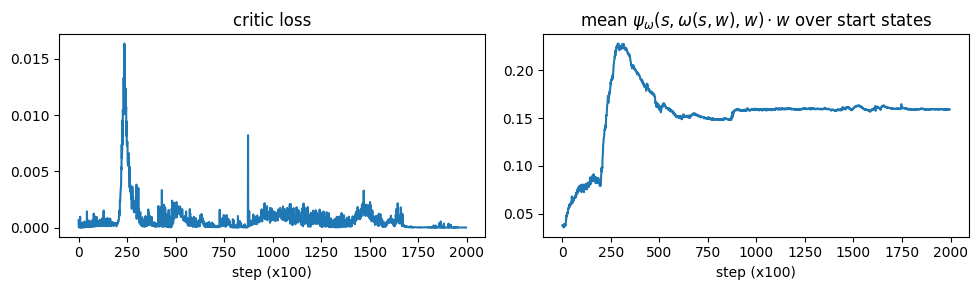

0.15908314074788774


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(losses)
axes[0].set_xlabel("step (x100)")
axes[0].set_title("critic loss")
axes[1].plot(value_snapshots)
axes[1].set_xlabel("step (x100)")
axes[1].set_title(r"mean $\psi_\omega(s,\omega(s,w),w)\cdot w$ over start states")
plt.tight_layout()
plt.show()

print(value_snapshots[-1])

In [12]:
omega_best, psi_omega_best = MetaPolicy(2, d), MetaCritic(2, d)
omega_best.load_state_dict(best_state[0])
psi_omega_best.load_state_dict(best_state[1])
print(f"best checkpoint: step={best_state[2]}  eval_return={best_state[3]:.4f}")

best_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega_best, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"ok_policy_best={best_val:.4f}  ok_policy_final={ok_val:.4f}  gpi_over_corners={gpi_val:.4f}")

best checkpoint: step=95000  eval_return=0.1589
ok_policy_best=0.1589  ok_policy_final=0.1584  gpi_over_corners=0.1660


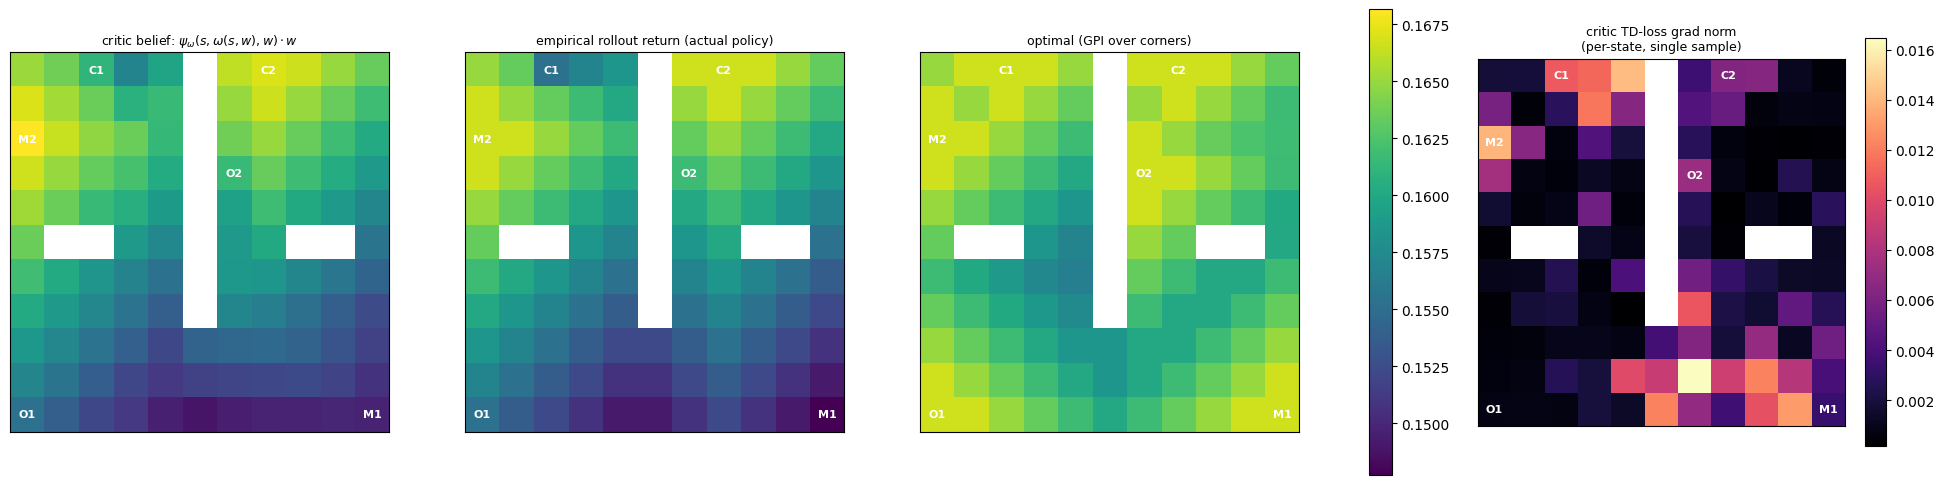

mean |critic belief - empirical|  = 0.0005   (critic calibration error)
mean |empirical - optimal|        = 0.0048   (actual policy suboptimality)
corr(suboptimality gap, critic grad norm) = 0.340


In [13]:
def value_map(w):
    w_t = torch.as_tensor(w, dtype=torch.float32).unsqueeze(0)
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            s_t = torch.as_tensor(office_env._normalize((r, c))).unsqueeze(0)
            with torch.no_grad():
                z = omega(s_t, w_t)
                vals[r, c] = (psi_omega(s_t, z, w_t) * w_t).sum().item()
    return vals


def empirical_value_map(w):
    # actual Monte-Carlo return from rolling out the trained policy from each state --
    # ground truth to compare against the critic's own belief (value_map) and the optimum.
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            vals[r, c] = rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w, omega, Pi_corners), state, w)
    return vals


def optimal_value_map(w, sf_tables=Pi_corners):
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            vals[r, c] = max((sft[state] @ w).max() for sft in sf_tables)
    return vals


def critic_grad_norm_map(w):
    # per-state critic TD-loss gradient norm: simulate one fresh transition from each
    # state under the current trained policy (on a separate env, same isolation reason
    # as eval_omega), then measure ||d critic_loss / d psi_omega_params|| for just that
    # single sample. Large values mean this state would still pull the critic hard right
    # now; near-zero means the loss has already settled there -- including the degenerate
    # case of a self-consistent but wrong fixed point (phi=0 forever, target=prediction=0).
    w_t = torch.as_tensor(w, dtype=torch.float32).unsqueeze(0)
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            o, _ = office_eval_env.reset(options={"state": state})
            s_t = torch.as_tensor(o, dtype=torch.float32).unsqueeze(0)
            with torch.no_grad():
                z = omega(s_t, w_t)
            a = gpi_action(rng_eval, state, z.squeeze(0).numpy(), Pi_corners)
            o_next, phi, term, trunc, _ = office_eval_env.step(a)
            s_next_t = torch.as_tensor(o_next, dtype=torch.float32).unsqueeze(0)
            phi_t = torch.as_tensor(phi, dtype=torch.float32).unsqueeze(0)
            done_t = torch.tensor([[float(term)]])

            with torch.no_grad():
                z_next = omega(s_next_t, w_t)
                target = phi_t + GAMMA * (1 - done_t) * psi_omega(s_next_t, z_next, w_t)

            psi_omega.zero_grad()
            loss = F.mse_loss(psi_omega(s_t, z, w_t), target)
            loss.backward()
            vals[r, c] = sum(p.grad.pow(2).sum().item() for p in psi_omega.parameters() if p.grad is not None) ** 0.5
    psi_omega.zero_grad()
    return vals


vals = value_map(w_uniform)
emp_vals = empirical_value_map(w_uniform)
opt_vals = optimal_value_map(w_uniform)
grad_vals = critic_grad_norm_map(w_uniform)
vmin, vmax = np.nanmin([vals, emp_vals, opt_vals]), np.nanmax([vals, emp_vals, opt_vals])

fig, axes = plt.subplots(1, 4, figsize=(width * 0.55 * 4, height * 0.55))
for ax, v, title in zip(axes[:3], [vals, emp_vals, opt_vals],
                         [r"critic belief: $\psi_\omega(s,\omega(s,w),w)\cdot w$",
                          "empirical rollout return (actual policy)",
                          "optimal (GPI over corners)"]):
    im = ax.imshow(v, cmap="viridis", vmin=vmin, vmax=vmax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_", "X"):
                ax.text(c, r, MAP[r, c], ha="center", va="center", fontsize=8, fontweight="bold", color="white")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=9)
fig.colorbar(im, ax=list(axes[:3]), fraction=0.02)

im2 = axes[3].imshow(grad_vals, cmap="magma")
for r in range(height):
    for c in range(width):
        if MAP[r, c] not in (" ", "_", "X"):
            axes[3].text(c, r, MAP[r, c], ha="center", va="center", fontsize=8, fontweight="bold", color="white")
axes[3].set_xticks([])
axes[3].set_yticks([])
axes[3].set_title("critic TD-loss grad norm\n(per-state, single sample)", fontsize=9)
fig.colorbar(im2, ax=axes[3], fraction=0.05)
plt.show()

print(f"mean |critic belief - empirical|  = {np.nanmean(np.abs(vals - emp_vals)):.4f}   (critic calibration error)")
print(f"mean |empirical - optimal|        = {np.nanmean(np.abs(emp_vals - opt_vals)):.4f}   (actual policy suboptimality)")

gap = np.abs(emp_vals - opt_vals)
mask = ~np.isnan(gap)
corr = np.corrcoef(gap[mask], grad_vals[mask])[0, 1]
print(f"corr(suboptimality gap, critic grad norm) = {corr:.3f}")

state=(0, 0)  obs=[0. 0.]  z=[0.    0.    0.    0.    0.    0.999]
state=(0, 1)  obs=[0.  0.1]  z=[0.    0.001 0.001 0.    0.027 0.972]
state=(0, 3)  obs=[0.  0.3]  z=[0.    0.019 0.001 0.    0.969 0.011]
state=(0, 4)  obs=[0.  0.4]  z=[0.    0.173 0.    0.    0.825 0.002]
state=(0, 6)  obs=[0.  0.6]  z=[0. 1. 0. 0. 0. 0.]
state=(0, 8)  obs=[0.  0.8]  z=[0. 1. 0. 0. 0. 0.]
state=(0, 9)  obs=[0.  0.9]  z=[0. 1. 0. 0. 0. 0.]
state=(0, 10)  obs=[0. 1.]  z=[0. 1. 0. 0. 0. 0.]
state=(1, 0)  obs=[0.1 0. ]  z=[0. 0. 0. 0. 0. 1.]
state=(1, 1)  obs=[0.1 0.1]  z=[0. 0. 0. 0. 0. 1.]
state=(1, 2)  obs=[0.1 0.2]  z=[0.    0.002 0.    0.    0.011 0.986]
state=(1, 3)  obs=[0.1 0.3]  z=[0.    0.076 0.    0.    0.36  0.564]
state=(1, 4)  obs=[0.1 0.4]  z=[0.    0.18  0.    0.    0.798 0.023]
state=(1, 6)  obs=[0.1 0.6]  z=[0. 1. 0. 0. 0. 0.]
state=(1, 7)  obs=[0.1 0.7]  z=[0. 1. 0. 0. 0. 0.]
state=(1, 8)  obs=[0.1 0.8]  z=[0. 1. 0. 0. 0. 0.]
state=(1, 9)  obs=[0.1 0.9]  z=[0. 1. 0. 0. 0. 0.]
state=(1, 

state=(8, 6)  obs=[0.8 0.6]  z=[0. 1. 0. 0. 0. 0.]
state=(8, 7)  obs=[0.8 0.7]  z=[0. 1. 0. 0. 0. 0.]
state=(8, 8)  obs=[0.8 0.8]  z=[0. 1. 0. 0. 0. 0.]
state=(8, 9)  obs=[0.8 0.9]  z=[0. 1. 0. 0. 0. 0.]
state=(8, 10)  obs=[0.8 1. ]  z=[0. 1. 0. 0. 0. 0.]
state=(9, 0)  obs=[0.9 0. ]  z=[0. 0. 0. 0. 0. 1.]
state=(9, 1)  obs=[0.9 0.1]  z=[0. 0. 0. 0. 0. 1.]
state=(9, 2)  obs=[0.9 0.2]  z=[0. 0. 0. 0. 0. 1.]
state=(9, 3)  obs=[0.9 0.3]  z=[0. 0. 0. 0. 0. 1.]
state=(9, 4)  obs=[0.9 0.4]  z=[0.    0.008 0.    0.    0.    0.992]
state=(9, 5)  obs=[0.9 0.5]  z=[0.   0.93 0.   0.   0.   0.07]
state=(9, 6)  obs=[0.9 0.6]  z=[0. 1. 0. 0. 0. 0.]
state=(9, 7)  obs=[0.9 0.7]  z=[0. 1. 0. 0. 0. 0.]
state=(9, 8)  obs=[0.9 0.8]  z=[0. 1. 0. 0. 0. 0.]
state=(9, 9)  obs=[0.9 0.9]  z=[0. 1. 0. 0. 0. 0.]
state=(9, 10)  obs=[0.9 1. ]  z=[0. 1. 0. 0. 0. 0.]
state=(10, 1)  obs=[1.  0.1]  z=[0. 0. 0. 0. 0. 1.]
state=(10, 2)  obs=[1.  0.2]  z=[0. 0. 0. 0. 0. 1.]
state=(10, 3)  obs=[1.  0.3]  z=[0. 0. 0. 0. 0. 

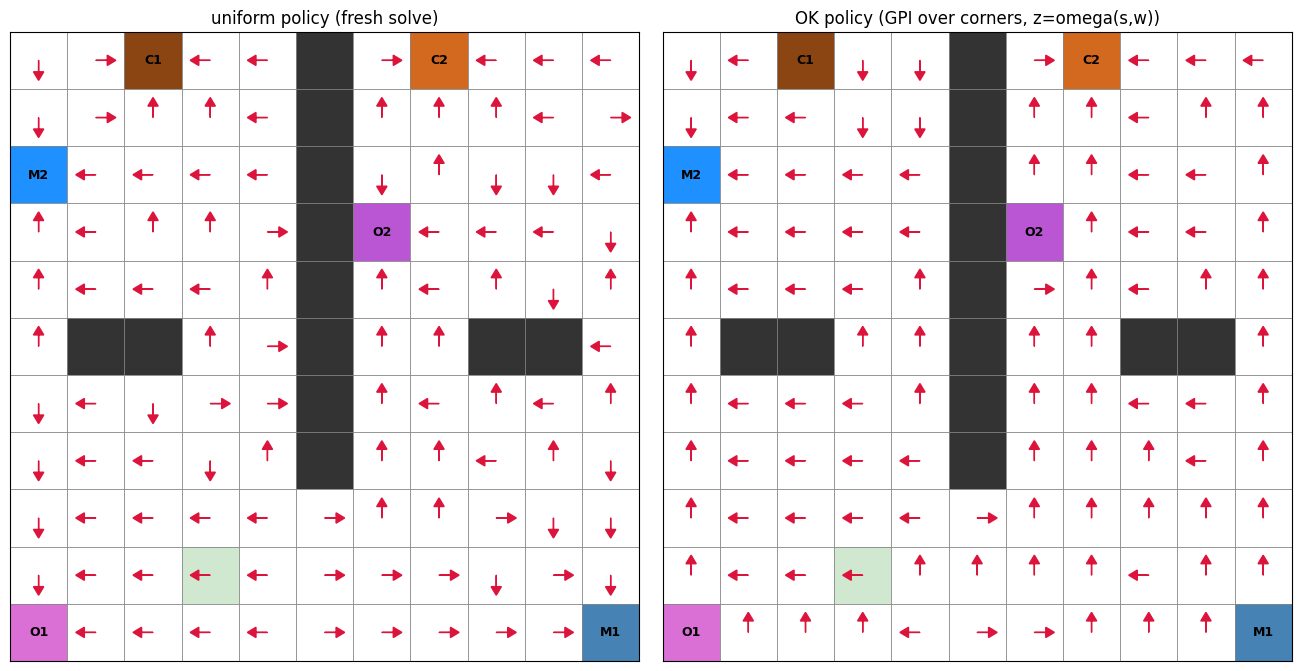

In [14]:
def ok_greedy_action(state):
    obs = office_env._normalize(state)
    with torch.no_grad():
        z = omega(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w_uniform).unsqueeze(0)).squeeze(0).numpy()
        print(f"state={state}  obs={obs}  z={z.round(3)}")
    values = np.stack([sft[state] @ z for sft in Pi_corners], axis=0)
    return int(values.max(axis=0).argmax())


def plot_arrows(ax, action_fn, arrow_len=0.35):
    draw_domain(ax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_"):
                continue
            action = action_fn((r, c))
            dcol, drow = ACTION_DELTAS[action]
            x, y = cell_center(r, c)
            ax.arrow(x, y, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=6)


fig, axes = plt.subplots(1, 2, figsize=(width * 0.6 * 2, height * 0.6))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], ok_greedy_action)
axes[1].set_title("OK policy (GPI over corners, z=omega(s,w))")
plt.tight_layout()
plt.show()

In [15]:
uniform_val = np.mean([rollout_value(office_env, lambda s, o: gpi_action(rng_eval, s, w_uniform, [pi_uniform]), s0, w_uniform) for s0 in starts])
ok_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"uniform_policy={uniform_val:.4f}  ok_policy={ok_val:.4f}")

uniform_policy=0.1660  ok_policy=0.1589


In [16]:
OBJECT_POS = [None] * d
for r in range(height):
    for c in range(width):
        sym = MAP[r, c]
        if sym in PHI_OBJ_TYPES:
            OBJECT_POS[PHI_OBJ_TYPES.index(sym)] = (r, c)


def deterministic_omega(state):
    # pure grid (Manhattan) distance from `state` to each object's actual map location --
    # no SF/Pi_corners involved at all, just "which exit is physically nearest".
    dists = [abs(state[0] - r) + abs(state[1] - c) for r, c in OBJECT_POS]
    label = int(np.argmin(dists))
    z = np.zeros(d, dtype=np.float32)
    z[label] = 1.0
    return z


def ok_action_det(rng, state, obs, sf_tables):
    z = deterministic_omega(state)
    return gpi_action(rng, state, z, sf_tables)


det_val = np.mean([rollout_value(office_env, lambda s, o: ok_action_det(rng_eval, s, o, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"deterministic_meta_policy={det_val:.4f}  gpi_over_corners={gpi_val:.4f}\n")

for s in starts:
    z = deterministic_omega(s)
    print(f"  state={s} ({MAP[s]!r})  nearest={PHI_OBJ_TYPES[int(z.argmax())]}")

deterministic_meta_policy=0.1660  gpi_over_corners=0.1660

  state=(2, 0) ('M2')  nearest=M2
  state=(10, 0) ('O1')  nearest=O1
  state=(0, 2) ('C1')  nearest=C1
  state=(9, 3) ('_')  nearest=O1
  state=(3, 6) ('O2')  nearest=O2
  state=(0, 7) ('C2')  nearest=C2
  state=(10, 10) ('M1')  nearest=M1


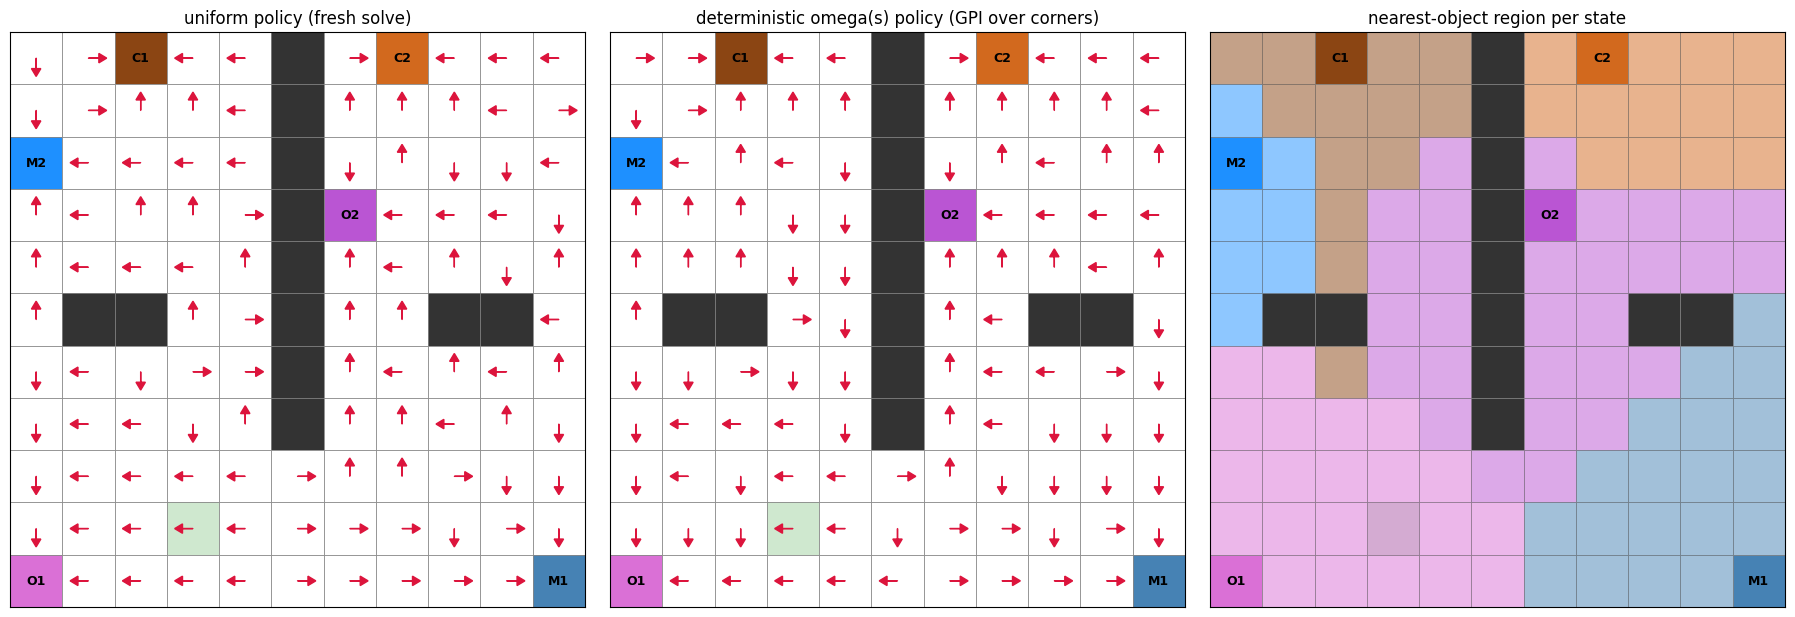

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(width * 0.55 * 3, height * 0.55))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], lambda s: ok_action_det(rng_eval, s, office_env._normalize(s), Pi_corners))
axes[1].set_title("deterministic omega(s) policy (GPI over corners)")

draw_domain(axes[2])
for r in range(height):
    for c in range(width):
        if MAP[r, c] not in (" ", "_"):
            continue
        z = deterministic_omega((r, c))
        color = object_colors[PHI_OBJ_TYPES[int(z.argmax())]]
        rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5, alpha=0.5)
        axes[2].add_patch(rect)
axes[2].set_title("nearest-object region per state")
plt.tight_layout()
plt.show()

In [18]:
class SupervisedMetaPolicy(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def forward(self, s):
        return F.softmax(self.net(s), dim=-1)


core_map = office_env.core.MAP
all_states = [(r, c) for r in range(core_map.shape[0]) for c in range(core_map.shape[1]) if core_map[r, c] != "X"]

X_sup = torch.stack([torch.as_tensor(office_env._normalize(s)) for s in all_states])
y_sup = torch.as_tensor([int(deterministic_omega(s).argmax()) for s in all_states])

torch.manual_seed(SEED)
omega_sup = SupervisedMetaPolicy(2, d)
opt_sup = torch.optim.Adam(omega_sup.parameters(), lr=1e-3)
for epoch in range(3000):
    logits = omega_sup.net(X_sup)
    loss = F.cross_entropy(logits, y_sup)
    opt_sup.zero_grad(); loss.backward(); opt_sup.step()

acc = (logits.argmax(-1) == y_sup).float().mean().item()
print(f"epochs=3000  loss={loss.item():.5f}  train_acc={acc:.3f}")
print("label counts:", {PHI_OBJ_TYPES[i]: int((y_sup == i).sum()) for i in range(d)})

epochs=3000  loss=0.00069  train_acc=1.000
label counts: {'C1': 14, 'C2': 14, 'O1': 23, 'O2': 30, 'M1': 20, 'M2': 8}


supervised_meta_policy=0.1660  gpi_over_corners=0.1660


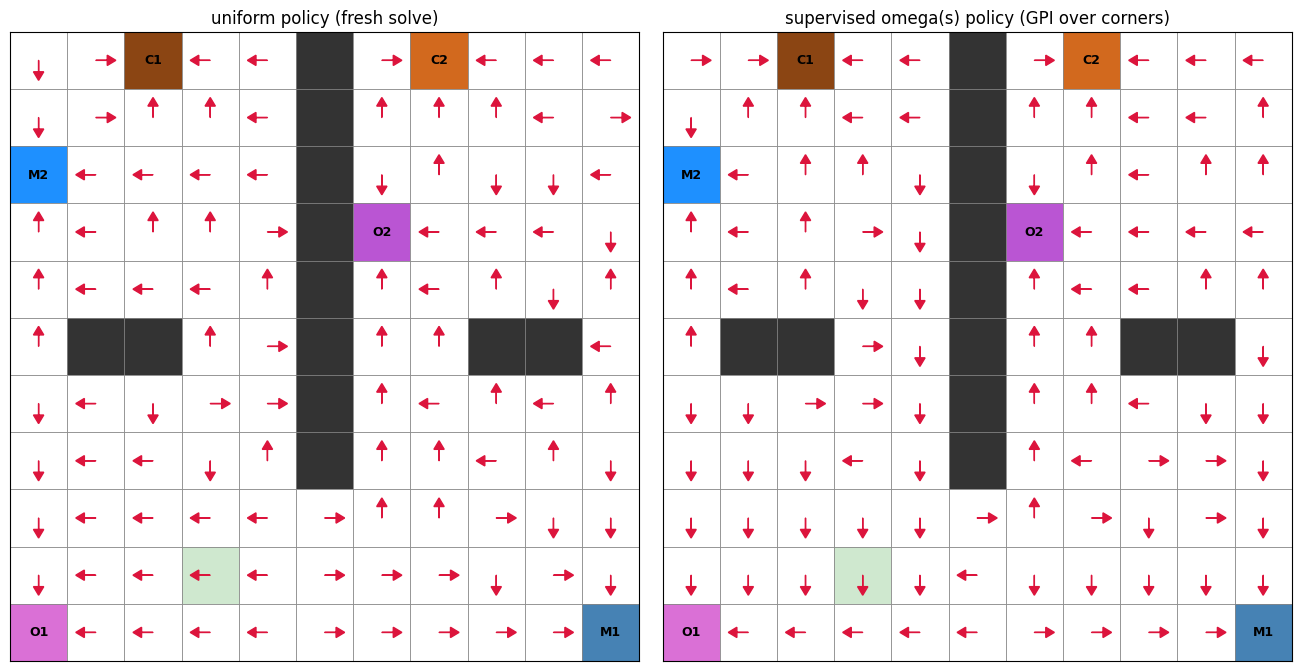

In [19]:
def ok_action_sup(rng, state, obs, sf_tables):
    with torch.no_grad():
        z = omega_sup(torch.as_tensor(obs).unsqueeze(0)).squeeze(0).numpy()
    return gpi_action(rng, state, z, sf_tables)


sup_val = np.mean([rollout_value(office_env, lambda s, o: ok_action_sup(rng_eval, s, o, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"supervised_meta_policy={sup_val:.4f}  gpi_over_corners={gpi_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(width * 0.6 * 2, height * 0.6))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], lambda s: ok_action_sup(rng_eval, s, office_env._normalize(s), Pi_corners))
axes[1].set_title("supervised omega(s) policy (GPI over corners)")
plt.tight_layout()
plt.show()